# 08 — Null comparison for candidate association

This is a conditional null comparison, not ground-truth validation. In the October 2025 archive slice, within each satellite × UTC day, shuffle the observed `(latitude, longitude)` pairs across that satellite's observation timestamps. This keeps each source's day-specific spatial density and observation-time distribution, while breaking the original coordinate-to-time pairing. Then count only MODIS–VIIRS candidate edges.

A high null count is plausible when source detections are spatially concentrated and multiple platforms observe the same active landscape. The empirical upper-tail fraction describes this chosen randomization only. It is not precision, recall, pairwise match probability, or evidence that any edge is a shared fire. The three thresholds are exploratory sensitivity points; no multiple-comparison inference is made.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.firewatch.association import find_candidate_links

SOURCE = ROOT / 'data' / 'processed' / 'observations.parquet'
OUT = ROOT / 'data' / 'processed' / 'null_comparison_oct2025.csv'
COLUMNS = ['observation_id','satellite','product_code','latitude_num','longitude_num','observation_datetime_utc','validation_status','stream_type']
obs = pd.read_parquet(SOURCE, columns=COLUMNS)
obs['observation_datetime_utc'] = pd.to_datetime(obs.observation_datetime_utc, utc=True)
start, end = pd.Timestamp('2025-10-01',tz='UTC'), pd.Timestamp('2025-11-01',tz='UTC')
study = obs.loc[obs.observation_datetime_utc.ge(start) & obs.observation_datetime_utc.lt(end) & obs.stream_type.eq('archive')].copy()
study['_utc_day'] = study.observation_datetime_utc.dt.floor('D')
print(f'{len(study):,} archive observations; platforms: {sorted(study.satellite.unique())}')


4,727 archive observations; platforms: ['Aqua', 'N20', 'N21', 'SNPP', 'Terra']


In [2]:
THRESHOLDS = [(0.5,1.0),(1.0,3.0),(2.0,6.0)]
N_PERMUTATIONS = 29
RANDOM_SEED = 20261114

def modis_viirs_count(frame, max_distance_km, max_time_delta_hours):
    links = find_candidate_links(frame, max_distance_km=max_distance_km, max_time_delta_hours=max_time_delta_hours)
    return int(links.link_family.eq('MODIS-VIIRS').sum())

observed = {(d,h):modis_viirs_count(study,d,h) for d,h in THRESHOLDS}
rng = np.random.default_rng(RANDOM_SEED)
records = []
groups = list(study.groupby(['satellite','_utc_day'], sort=False).groups.values())
for replicate in range(1, N_PERMUTATIONS + 1):
    randomized = study.copy()
    for idx in groups:
        coords = study.loc[idx,['latitude_num','longitude_num']].to_numpy()
        randomized.loc[idx,['latitude_num','longitude_num']] = coords[rng.permutation(len(coords))]
    for distance, hours in THRESHOLDS:
        records.append({'replicate':replicate,'seed':RANDOM_SEED,'max_distance_km':distance,
                        'max_time_delta_hours':hours,'null_MODIS_VIIRS_edges':modis_viirs_count(randomized,distance,hours)})
    if replicate % 5 == 0: print(f'completed {replicate}/{N_PERMUTATIONS} permutations')
null = pd.DataFrame(records)
null.to_csv(OUT,index=False)
print('saved:', OUT)


completed 5/29 permutations


completed 10/29 permutations


completed 15/29 permutations


completed 20/29 permutations


completed 25/29 permutations


saved: C:\Users\ngong\Documents\NASA CHALLENGE\data\processed\null_comparison_oct2025.csv


,max_distance_km,max_time_delta_hours,observed_MODIS_VIIRS_edges,null_mean,null_sd,null_q025,null_median,null_q975,observed_to_null_mean_ratio,empirical_upper_tail_fraction
0,0.5,1.0,24,22.724,0.996,21.0,23.0,24.3,1.056,0.233
1,1.0,3.0,332,321.862,2.800,317.0,322.0,326.6,1.031,0.033
2,2.0,6.0,909,902.138,6.728,892.0,902.0,912.5,1.008,0.233


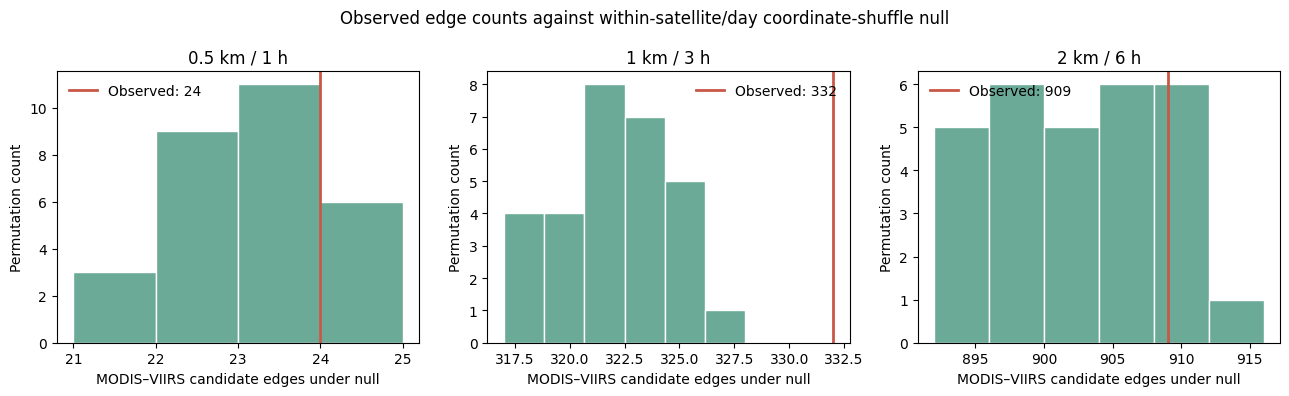

In [3]:
summary_rows=[]
for (distance,hours), actual in observed.items():
    values = null.loc[null.max_distance_km.eq(distance) & null.max_time_delta_hours.eq(hours),'null_MODIS_VIIRS_edges']
    summary_rows.append({'max_distance_km':distance,'max_time_delta_hours':hours,'observed_MODIS_VIIRS_edges':actual,
        'null_mean':values.mean(),'null_sd':values.std(ddof=1),'null_q025':values.quantile(.025),
        'null_median':values.median(),'null_q975':values.quantile(.975),
        'observed_to_null_mean_ratio':actual/values.mean(),
        'empirical_upper_tail_fraction':(1 + int((values >= actual).sum()))/(N_PERMUTATIONS+1)})
summary=pd.DataFrame(summary_rows)
display(summary.round(3))
fig, axes=plt.subplots(1,3,figsize=(13,4),sharey=False)
for ax, ((distance,hours), actual) in zip(axes,observed.items()):
    values=null.loc[null.max_distance_km.eq(distance) & null.max_time_delta_hours.eq(hours),'null_MODIS_VIIRS_edges']
    ax.hist(values,bins='auto',color='#6caa98',edgecolor='white')
    ax.axvline(actual,color='#c95748',linewidth=2,label=f'Observed: {actual}')
    ax.set_title(f'{distance:g} km / {hours:g} h')
    ax.set_xlabel('MODIS–VIIRS candidate edges under null')
    ax.set_ylabel('Permutation count')
    ax.legend(frameon=False)
fig.suptitle('Observed edge counts against within-satellite/day coordinate-shuffle null')
fig.tight_layout(); plt.show()


## Read this result cautiously

This null preserves each satellite's daily set of locations and timestamp distribution; it does not model scan geometry, pixel footprints, detection probability, geolocation error, fire growth, or source dependence. Because shared burning landscapes can create spatially concentrated detections, the null may retain substantial cross-sensor proximity even after coordinate-to-time pairing is shuffled. The observed-minus-null contrast therefore has a narrow interpretation under these assumptions.

The 29 permutations give a coarse empirical tail estimate (resolution 1/30). Results are sensitive to this null design, month, and threshold. Do not use the empirical tail fraction to select an “optimal” matching threshold. Next validation requires independently labeled co-observations or an explicit sensor-overpass/coverage reference, plus broader null designs.
